# 🫁 Pneumonia Detection from Chest X-Ray Images using CNN

**Google Colab-ready version**

**A reproducible deep-learning pipeline built with TensorFlow / Keras**

> ⚠️ **Disclaimer** – This notebook is an **educational and experimental** project. The model is **not** a medical device and must **never** be used for clinical diagnosis or treatment decisions.

---

## Table of Contents
1. [Introduction](#part-1)
2. [Environment Setup](#part-2)
3. [Dataset Exploration](#part-3)
4. [Data Preprocessing](#part-4)
5. [CNN Model Architecture](#part-5)
6. [Model Training](#part-6)
7. [Model Evaluation](#part-7)
8. [Performance Visualization](#part-8)
9. [Prediction on New Images](#part-9)
10. [Conclusion](#part-10)

<a id="part-1"></a>
# PART 1 – Introduction

## 1.1 Project Overview
Pneumonia is an infection of the lungs that is commonly assessed with chest radiographs. This project trains a **Convolutional Neural Network (CNN) from scratch** to classify chest X-ray images into two categories, and evaluates it rigorously on a held-out test set.

## 1.2 Problem Statement
Given a single chest X-ray image, predict whether it belongs to a **NORMAL** subject or to a patient with **PNEUMONIA** (bacterial or viral – the dataset groups both under one label).

## 1.3 Objectives
- Build a clean, memory-efficient `tf.data` input pipeline.
- Avoid **data leakage** (strict train / validation / test separation).
- Handle **class imbalance** with class weights.
- Train a compact CNN with regularisation and sensible callbacks.
- Evaluate honestly with several metrics (not accuracy alone).
- Save the best model to disk so it can be reloaded **without retraining**.

## 1.4 Task Definition
| Item | Value |
|---|---|
| Task | Binary image classification |
| Classes | `NORMAL` (label 0) vs `PNEUMONIA` (label 1) |
| Positive class | `PNEUMONIA` |
| Input | Chest X-ray resized to 224 × 224 × 3 |
| Output | Probability of pneumonia (sigmoid) |

## 1.5 Dataset
**Chest X-Ray Images (Pneumonia)** by Paul Mooney – <https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia>

The images come from pediatric patients (1–5 years old) at the Guangzhou Women and Children's Medical Center (Kermany et al., *Cell*, 2018). The Hugging Face mirror provides `train`, `validation`, and `test` splits with `NORMAL` and `PNEUMONIA` labels; this notebook exports the train and test images into folders for the TensorFlow pipeline. **All counts used in this notebook are computed at runtime from your local copy.**

## 1.6 Technologies Used
| Library | Purpose |
|---|---|
| Python 3 | Programming language |
| TensorFlow / Keras | CNN model and `tf.data` pipeline |
| NumPy, Pandas | Numerical computing and tabular data |
| Matplotlib, Seaborn | Visualisation |
| Scikit-learn | Metrics, class weights, grouped splitting |
| Pillow | Reading image metadata |

<a id="part-2"></a>
# PART 2 – Environment Setup
We import the libraries, display their versions, check GPU availability and centralise every tunable parameter in one configuration cell.

In [1]:
import json
import os
import random
import re
import sys
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import tensorflow as tf
from IPython.display import Markdown, display
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})


In [2]:
# Library versions (useful for reproducibility)
versions = pd.DataFrame({
    "Library": ["Python", "TensorFlow", "Keras", "NumPy", "Pandas", "Matplotlib", "Seaborn", "Scikit-learn"],
    "Version": [sys.version.split()[0], tf.__version__, keras.__version__, np.__version__,
                pd.__version__, plt.matplotlib.__version__, sns.__version__, sklearn.__version__],
})
display(versions)

# GPU availability (memory growth avoids grabbing all GPU memory up-front)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as err:  # must be set before the GPU is initialised
        print("Could not set memory growth:", err)
    print(f"✅ {len(gpus)} GPU(s) detected: {[g.name for g in gpus]}")
else:
    print("ℹ️ No GPU detected – training will run on CPU (slower, but fully functional).")

,Library,Version
0,Python,3.13.18
1,TensorFlow,2.21.0
2,Keras,3.13.2
3,NumPy,2.4.6
4,Pandas,2.2.3
5,Matplotlib,3.10.0
6,Seaborn,0.13.2
7,Scikit-learn,1.6.1


ℹ️ No GPU detected – training will run on CPU (slower, but fully functional).


In [3]:
# ----------------------------- Configuration -----------------------------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = int(os.environ.get("EPOCHS", 20))
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.15
THRESHOLD = 0.5

# Reuse an existing best model by default. Set RETRAIN=True to start a fresh run.
RETRAIN = False

# If a previous run was interrupted AND its BackupAndRestore folder exists,
# set RESUME_FROM_BACKUP=True before running the training cell.
RESUME_FROM_BACKUP = False

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]  # label 0 = NORMAL, label 1 = PNEUMONIA
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

MODEL_DIR = Path("/content/models") if Path("/content").exists() else Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = MODEL_DIR / "best_pneumonia_cnn.keras"
HISTORY_PATH = MODEL_DIR / "training_history.json"
BACKUP_DIR = MODEL_DIR / "training_backup"

keras.utils.set_random_seed(SEED)
print("Configuration loaded. Seed =", SEED)
print("Model directory:", MODEL_DIR.resolve())


Configuration loaded. Seed = 42
Model directory: /content/models


<a id="part-3"></a>
# PART 3 – Dataset Exploration

## 3.1 Download the Dataset (Google Colab)
This notebook can download the public dataset directly inside Colab from its Hugging Face mirror. You do **not** need to upload a 2 GB ZIP file from your computer or create a Kaggle API token.

Dataset: [Chest X-Ray Pneumonia – Hugging Face](https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia)

The mirror contains `train`, `validation`, and `test` splits. The original validation split has only 16 images, so this notebook uses the original `train` split to create a larger stratified validation subset and keeps the original `test` split for final evaluation. The images are cached/downloaded by Colab and copied into a folder structure required by the `tf.data` pipeline.

Expected local layout:
```text
/content/data/chest_xray/
├── train/
│   ├── NORMAL/
│   └── PNEUMONIA/
└── test/
    ├── NORMAL/
    └── PNEUMONIA/
```

The dataset download is about 1.23 GB. It is downloaded by the Colab runtime, not uploaded from your Windows computer.


In [4]:
# Install the dataset loader (no Kaggle API token required)
!pip -q install datasets


In [5]:
# This cell is intentionally kept separate so the installation above finishes first.
print("✅ Dataset loader is ready.")


✅ Dataset loader is ready.


In [6]:
from pathlib import Path

def has_required_structure(root):
    root = Path(root)
    expected_counts = {
        ("train", "NORMAL"): 1341,
        ("train", "PNEUMONIA"): 3875,
        ("test", "NORMAL"): 234,
        ("test", "PNEUMONIA"): 390,
    }

    for (split, class_name), expected in expected_counts.items():
        folder = root / split / class_name
        if not folder.is_dir():
            return False
        actual = sum(
            1 for path in folder.iterdir()
            if path.is_file() and path.suffix.lower() in {".jpeg", ".jpg", ".png"}
        )
        if actual != expected:
            return False

    return True

def find_data_dir():
    # Common locations used by Colab, local Jupyter, and Kaggle.
    candidates = [
        Path(os.environ["PNEUMONIA_DATA_DIR"]) if os.environ.get("PNEUMONIA_DATA_DIR") else None,
        Path("/content/data/chest_xray"),
        Path("/content/data/chest_xray/chest_xray"),
        Path("/content/data/hf_chest_xray"),
        Path("/content/data"),
        Path("data/chest_xray"),
        Path("data/chest_xray/chest_xray"),
        Path("chest_xray"),
        Path("/kaggle/input/chest-xray-pneumonia/chest_xray"),
    ]

    for candidate in candidates:
        if candidate is not None and has_required_structure(candidate):
            return candidate.resolve()

    return None


DATA_DIR = find_data_dir()

if DATA_DIR is None:
    print("Dataset not found locally. Downloading the public Hugging Face copy...")
    from datasets import load_dataset
    from tqdm.auto import tqdm

    HF_DATASET_ID = "hf-vision/chest-xray-pneumonia"
    raw_dataset = load_dataset(HF_DATASET_ID)

    DATA_DIR = Path("/content/data/chest_xray")
    DATA_DIR.mkdir(parents=True, exist_ok=True)

    # Save train and test images to disk. The tiny original validation split
    # (16 images) is intentionally not used; validation is created from train.
    split_map = {"train": "train", "test": "test"}

    for source_split, target_split in split_map.items():
        split_data = raw_dataset[source_split]
        label_feature = split_data.features["label"]

        for index, example in enumerate(tqdm(split_data, desc=f"Preparing {target_split}")):
            label_name = label_feature.int2str(int(example["label"])).upper()
            if label_name not in CLASS_NAMES:
                raise ValueError(f"Unexpected class label: {label_name}")

            image = example["image"]
            if image is None:
                raise ValueError(f"Missing image at {source_split} row {index}")

            output_dir = DATA_DIR / target_split / label_name
            output_dir.mkdir(parents=True, exist_ok=True)
            output_path = output_dir / f"{label_name.lower()}_{index:05d}.jpg"

            if not output_path.exists():
                image.convert("RGB").save(output_path, format="JPEG", quality=95)

    if not has_required_structure(DATA_DIR):
        raise FileNotFoundError(
            "The dataset was downloaded, but the expected train/test class folders are missing."
        )

print("✅ Dataset found at:", DATA_DIR.resolve())

for split in ("train", "test"):
    print(f"\n{split.upper()}")
    for class_name in CLASS_NAMES:
        folder = DATA_DIR / split / class_name
        count = sum(1 for p in folder.iterdir() if p.suffix.lower() in {".jpeg", ".jpg", ".png"})
        print(f"  {class_name}: {count:,} images")


✅ Dataset found at: /content/data/chest_xray

TRAIN
  NORMAL: 1,341 images
  PNEUMONIA: 3,875 images

TEST
  NORMAL: 234 images
  PNEUMONIA: 390 images


## 3.2 Folder Structure and File Inventory
We build a Pandas `DataFrame` that lists **every image path** with its split and label. Only file paths are stored – no pixel data – so memory usage stays negligible.

The Hugging Face mirror stores image pixels and class labels, but does not expose the original patient identifiers or original filenames. For that reason, this notebook does not claim to perform patient-level grouping; it uses a stratified train/validation split instead.


In [7]:
IMG_EXTS = {".jpeg", ".jpg", ".png"}

records = []
for split in ["train", "val", "test"]:
    for label in CLASS_NAMES:
        folder = DATA_DIR / split / label
        if not folder.is_dir():
            if split == "val":
                continue
            raise FileNotFoundError(f"Missing required folder: {folder}")

        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in IMG_EXTS:
                records.append({
                    "path": str(path),
                    "split": split,
                    "label": label,
                    "label_id": CLASS_TO_ID[label],
                })

df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError("No images found – check the dataset folder structure.")

print(f"Total images found: {len(df):,}")
counts = pd.crosstab(df["split"], df["label"], margins=True, margins_name="Total")
display(counts)


Total images found: 5,840


label,NORMAL,PNEUMONIA,Total
split,,,
test,234,390,624
train,1341,3875,5216
Total,1575,4265,5840


In [8]:
# Reference counts for the public Hugging Face mirror.
# A mismatch is reported as a warning, not an error (e.g. a partial download).
REFERENCE = {
    ("train", "NORMAL"): 1341,
    ("train", "PNEUMONIA"): 3875,
    ("test", "NORMAL"): 234,
    ("test", "PNEUMONIA"): 390,
}
for (split, label), expected in REFERENCE.items():
    found = int(((df["split"] == split) & (df["label"] == label)).sum())
    status = "✅" if found == expected else "⚠️"
    print(f"{status} {split:5s} {label:9s} expected={expected:5d}  found={found:5d}")


✅ train NORMAL    expected= 1341  found= 1341
✅ train PNEUMONIA expected= 3875  found= 3875
✅ test  NORMAL    expected=  234  found=  234
✅ test  PNEUMONIA expected=  390  found=  390


## 3.3 Class Distribution
The dataset is **imbalanced**: pneumonia images clearly outnumber normal ones. A model that always predicts `PNEUMONIA` would already look decent in accuracy, which is why we will also track precision, recall, F1-score and AUC, and use class weights.

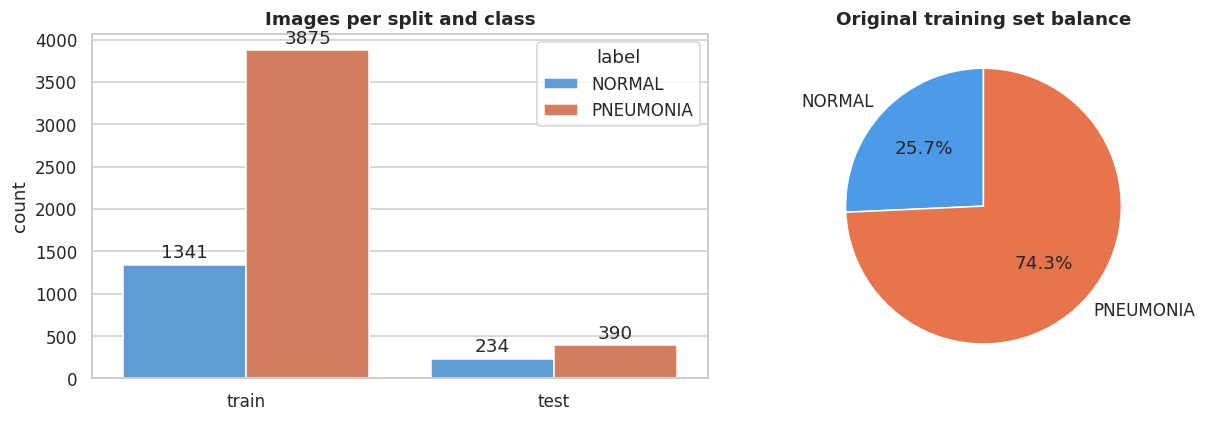

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = [s for s in ["train", "val", "test"] if s in df["split"].unique()]
sns.countplot(data=df, x="split", hue="label", order=order, hue_order=CLASS_NAMES,
              palette=["#4C9BE8", "#E8744C"], ax=axes[0])
axes[0].set_title("Images per split and class")
axes[0].set_xlabel("")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=2)

train_counts = df[df["split"] == "train"]["label"].value_counts().reindex(CLASS_NAMES)
axes[1].pie(train_counts, labels=train_counts.index, autopct="%1.1f%%", startangle=90,
            colors=["#4C9BE8", "#E8744C"], wedgeprops={"edgecolor": "white"})
axes[1].set_title("Original training set balance")
plt.tight_layout()
plt.show()

## 3.4 Sample Images

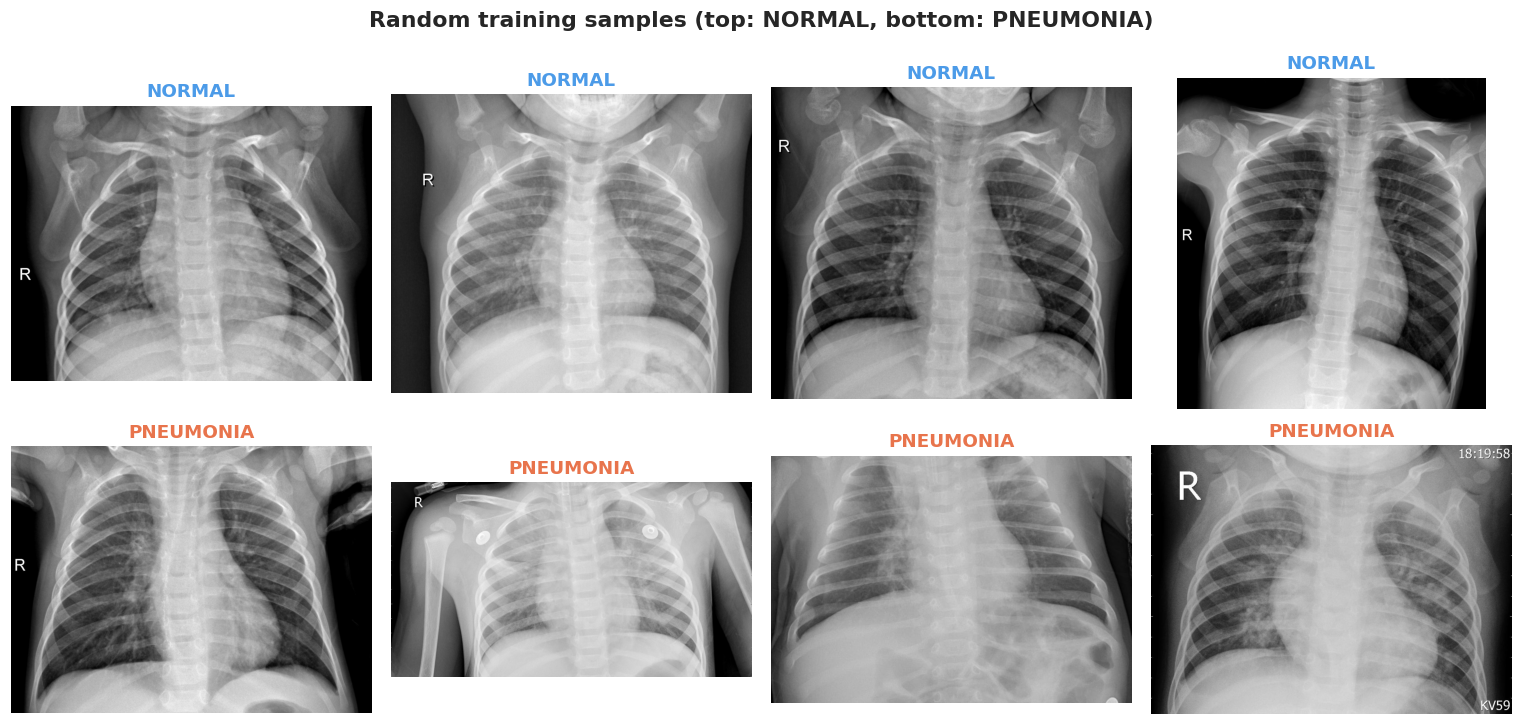

In [10]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, label in enumerate(CLASS_NAMES):
    subset = df[(df["split"] == "train") & (df["label"] == label)]
    for col, idx in enumerate(rng.choice(len(subset), size=4, replace=False)):
        img = Image.open(subset.iloc[idx]["path"])
        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(label, color="#E8744C" if label == "PNEUMONIA" else "#4C9BE8")
        axes[row, col].axis("off")
plt.suptitle("Random training samples (top: NORMAL, bottom: PNEUMONIA)", fontweight="bold")
plt.tight_layout()
plt.show()

## 3.5 Image Dimensions and Formats
Pillow reads only the image **header** when opening a file, so we can collect sizes and modes for every image without loading pixel data into memory.

,width,height
count,5840.0,5840.0
mean,1327.8,970.6
std,363.8,383.7
min,384.0,127.0
25%,1056.0,688.0
50%,1281.0,886.0
75%,1560.0,1187.0
max,2916.0,2713.0



Colour modes:
 mode
RGB    5840

File formats:
 format
JPEG    5840


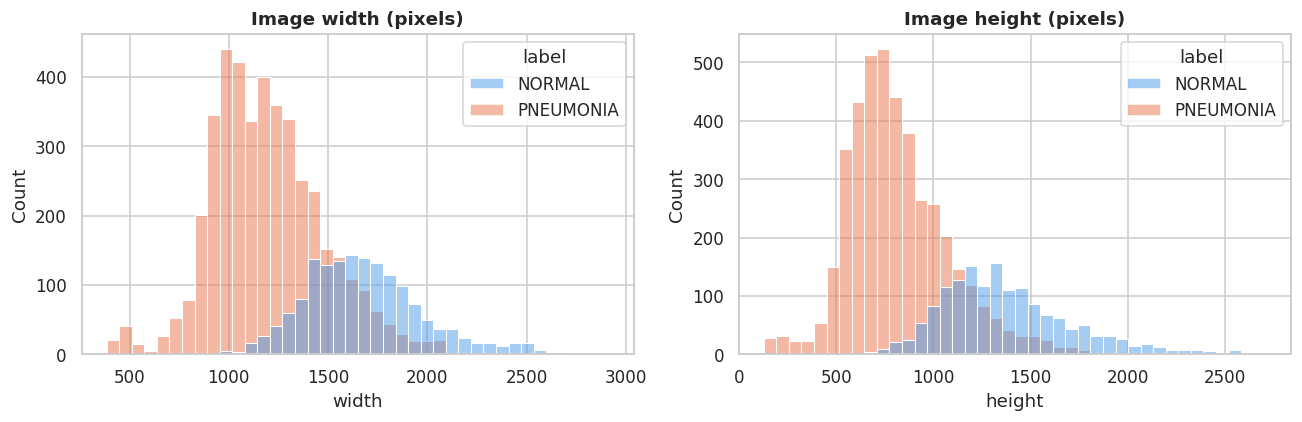

In [11]:
def read_meta(path):
    with Image.open(path) as img:
        return img.width, img.height, img.mode, img.format


meta = [read_meta(p) for p in df["path"]]
df[["width", "height", "mode", "format"]] = pd.DataFrame(meta, index=df.index)

display(df[["width", "height"]].describe().round(1))
print("\nColour modes:\n", df["mode"].value_counts().to_string())
print("\nFile formats:\n", df["format"].value_counts().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="width", hue="label", bins=40, palette=["#4C9BE8", "#E8744C"], ax=axes[0])
sns.histplot(data=df, x="height", hue="label", bins=40, palette=["#4C9BE8", "#E8744C"], ax=axes[1])
axes[0].set_title("Image width (pixels)")
axes[1].set_title("Image height (pixels)")
plt.tight_layout()
plt.show()

**Observations**
- Image sizes vary widely, so every image must be resized to a fixed shape.
- Images may be grayscale (`L`) or RGB; decoding with `channels=3` gives a consistent 3-channel input.

<a id="part-4"></a>
# PART 4 – Data Preprocessing

## 4.1 Splitting Strategy
| Set | Source | Use |
|---|---|---|
| **Train** | 85 % of the Hugging Face `train` split | Fit the model weights |
| **Validation** | 15 % of the Hugging Face `train` split | Early stopping, checkpointing and learning-rate scheduling |
| **Test** | Original `test` split | Final held-out evaluation |

The Hugging Face Parquet mirror provides image pixels and class labels, but does not expose the original patient identifiers or image filenames. Therefore, a patient-level split cannot be guaranteed from this mirror. We use a **stratified random split** so both classes remain represented in train and validation. The original test split remains separate and is not used for training or threshold tuning.


In [12]:
train_pool = df[df["split"] == "train"].reset_index(drop=True)
df_test = df[df["split"] == "test"].reset_index(drop=True)

df_train, df_val = train_test_split(
    train_pool,
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=train_pool["label_id"],
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

# ---- Leakage checks: image paths are disjoint across all sets ----
assert set(df_train["path"]).isdisjoint(df_val["path"]), "Train/validation overlap"
assert set(df_train["path"]).isdisjoint(df_test["path"]), "Train/test overlap"
assert set(df_val["path"]).isdisjoint(df_test["path"]), "Validation/test overlap"
print("✅ Train, validation and test image paths are disjoint.")

summary = pd.DataFrame({
    name: part["label"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
    for name, part in {"Train": df_train, "Validation": df_val, "Test": df_test}.items()
}).T
summary["Total"] = summary.sum(axis=1)
summary["% PNEUMONIA"] = (100 * summary["PNEUMONIA"] / summary["Total"]).round(1)
display(summary)


✅ Train, validation and test image paths are disjoint.


label,NORMAL,PNEUMONIA,Total,% PNEUMONIA
Train,1140,3293,4433,74.3
Validation,201,582,783,74.3
Test,234,390,624,62.5


## 4.2 Class Imbalance
The classes are imbalanced. Instead of discarding or duplicating images, we use **balanced class weights** computed on the **training subset only**. This increases the contribution of the minority class to the training loss.


In [13]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=df_train["label_id"].values)
CLASS_WEIGHT = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

Class weights: {'NORMAL': 1.944, 'PNEUMONIA': 0.673}


## 4.3 Memory-Efficient `tf.data` Pipeline
Images are **never all loaded into RAM**. The pipeline streams batches from disk:

1. Read the file and decode it as **3-channel RGB** (grayscale images are replicated across channels).
2. **Resize** to 224 × 224.
3. *(Training only)* apply **data augmentation**: small rotations, zoom, translation and contrast changes. Horizontal flips are deliberately **not** used, because anatomical orientation (e.g. heart position) is meaningful in chest X-rays.
4. Batch and prefetch.

**Pixel normalisation** (scaling to `[0, 1]`) is performed by the first layer of the model (`Rescaling`). This keeps the saved `.keras` file self-contained: the same preprocessing is guaranteed at training, evaluation and inference time.

In [14]:
AUTOTUNE = tf.data.AUTOTUNE

# Augmentation is used ONLY for the training set
augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10),
], name="augmentation")


def decode_and_resize(path):
    """Read an image file -> RGB float32 tensor of shape IMG_SIZE x 3 (values in [0, 255])."""
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(img, IMG_SIZE)


def load_example(path, label):
    return decode_and_resize(path), tf.cast(label, tf.float32)


def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].astype(str).values, frame["label_id"].values))
    if training:  # shuffling file paths is cheap (no pixels yet)
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_example, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(df_train, training=True)
val_ds = make_dataset(df_val)
test_ds = make_dataset(df_test)      # order preserved -> aligned with df_test

images, labels = next(iter(train_ds))
print("Batch shape:", images.shape, "| labels:", labels.shape,
      "| pixel range:", float(tf.reduce_min(images)), "-", float(tf.reduce_max(images)))

Batch shape: (32, 224, 224, 3) | labels: (32,) | pixel range: 0.0 - 255.0


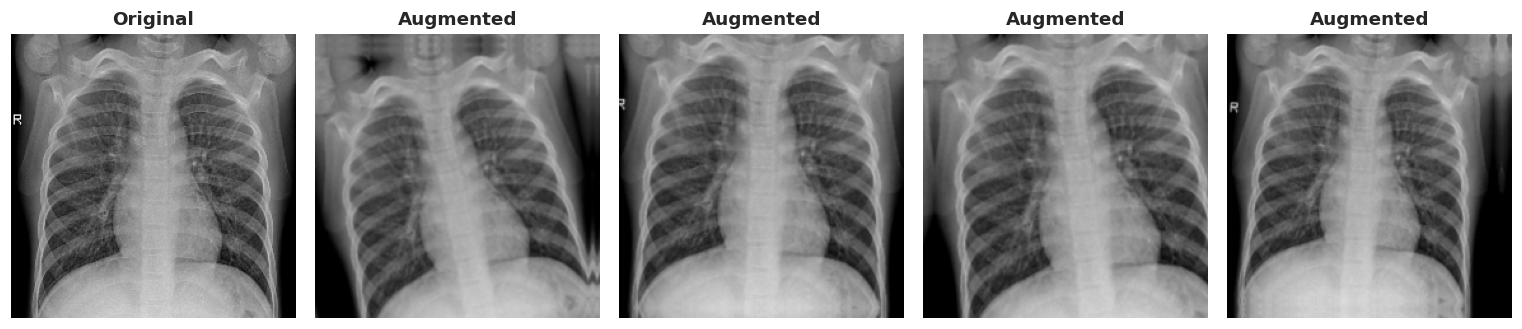

In [15]:
# Visual check of the augmentation applied to one training image
sample_path = df_train.iloc[0]["path"]
base = decode_and_resize(sample_path)
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(base.numpy().astype("uint8")); axes[0].set_title("Original")
for ax in axes[1:]:
    aug = augmentation(base, training=True)
    ax.imshow(tf.clip_by_value(aug, 0, 255).numpy().astype("uint8")); ax.set_title("Augmented")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

<a id="part-5"></a>
# PART 5 – CNN Model Architecture
A compact CNN is trained **from scratch**. With roughly five thousand training images, a small network with strong regularisation is a sensible choice and keeps training affordable.

| Layer | Role |
|---|---|
| `Rescaling(1/255)` | Normalises pixel values to `[0, 1]` (part of the saved model). |
| `Conv2D` (3×3) | Learns local filters (edges, textures, opacities). Filters grow 32 → 64 → 128 → 256 so deeper layers capture more abstract patterns. |
| `BatchNormalization` | Stabilises and speeds up training; has a mild regularising effect. |
| `ReLU` | Non-linearity that lets the network model complex patterns. |
| `MaxPooling2D` | Halves the spatial resolution, adds small translation invariance and reduces computation. |
| `Dropout` | Randomly disables neurons during training to limit overfitting. |
| `GlobalAveragePooling2D` | Collapses each feature map to one value – far fewer parameters than `Flatten`. |
| `Dense(128, ReLU)` | Combines the extracted features for the decision. |
| `Dense(1, sigmoid)` | Outputs the probability of `PNEUMONIA` ∈ [0, 1]. |

In [16]:
def build_cnn(input_shape=(*IMG_SIZE, 3)):
    inputs = keras.Input(shape=input_shape, name="xray")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)

    for i, filters in enumerate([32, 64, 128, 256], start=1):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv{i}")(x)
        x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.Activation("relu", name=f"relu{i}")(x)
        x = layers.MaxPooling2D(name=f"pool{i}")(x)
        if i >= 3:
            x = layers.Dropout(0.25, name=f"drop{i}")(x)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, activation="relu", name="dense")(x)
    x = layers.Dropout(0.5, name="drop_head")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)
    return keras.Model(inputs, outputs, name="pneumonia_cnn")


model = build_cnn()
model.summary()

Model: "pneumonia_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop4 (Dropout)                 │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_head (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_prob (Dense)          │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

<a id="part-6"></a>
# PART 6 – Model Training

## Training setup
- **Loss:** Binary Crossentropy · **Optimizer:** Adam · **Metrics:** accuracy, precision, recall, AUC
- **EarlyStopping** – stops when validation loss stops improving and restores the best weights.
- **ModelCheckpoint** – saves the best model (lowest validation loss) to `models/best_pneumonia_cnn.keras`.
- **ReduceLROnPlateau** – reduces the learning rate when validation loss plateaus.
- **BackupAndRestore** – stores completed-epoch training state so a future run can resume if interrupted.

**Reuse by default:** if a saved best model exists and `RETRAIN = False`, training is skipped. If a run was interrupted and its backup folder exists, set `RESUME_FROM_BACKUP = True` and run this cell again. The earlier run in this conversation did not have BackupAndRestore enabled, so its saved best checkpoint can be evaluated, but the exact interrupted epoch cannot be resumed.


In [17]:
history_dict = None

if BEST_MODEL_PATH.exists() and not RETRAIN and not RESUME_FROM_BACKUP:
    print(f"✅ Found saved model at '{BEST_MODEL_PATH}' – skipping training.")
    best_model = keras.models.load_model(BEST_MODEL_PATH)
    model = best_model
    if HISTORY_PATH.exists():
        history_dict = json.loads(HISTORY_PATH.read_text(encoding="utf-8"))
    else:
        print("ℹ️ No saved training history was found; training curves will be skipped.")

else:
    if RESUME_FROM_BACKUP and not BACKUP_DIR.exists():
        raise FileNotFoundError(
            f"No training backup found at {BACKUP_DIR}. "
            "Set RESUME_FROM_BACKUP=False to train normally or load the saved best model."
        )

    if RETRAIN and not RESUME_FROM_BACKUP:
        # A deliberate fresh run should not reuse an old interrupted backup.
        if BACKUP_DIR.exists():
            shutil.rmtree(BACKUP_DIR)

    model = build_cnn()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )

    callbacks = [
        keras.callbacks.BackupAndRestore(backup_dir=str(BACKUP_DIR)),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            str(BEST_MODEL_PATH), monitor="val_loss", save_best_only=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
        ),
    ]

    try:
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            class_weight=CLASS_WEIGHT,
            callbacks=callbacks,
            verbose=1,
        )
    except KeyboardInterrupt:
        print("\n⚠️ Training was interrupted. This is an execution stop, not a Python syntax error.")
        if BEST_MODEL_PATH.exists():
            best_model = keras.models.load_model(BEST_MODEL_PATH)
            model = best_model
            print("✅ Loaded the best checkpoint saved before the interruption.")
        else:
            print("⚠️ No best checkpoint exists yet. Run the training cell again to continue from BackupAndRestore.")
        history_dict = None
    else:
        history_dict = {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        }
        HISTORY_PATH.write_text(json.dumps(history_dict, indent=2), encoding="utf-8")
        best_model = keras.models.load_model(BEST_MODEL_PATH)
        model = best_model
        print(
            f"\n✅ Training finished after {len(history_dict['loss'])} epoch(s). "
            f"Best model saved to '{BEST_MODEL_PATH}'."
        )


✅ Found saved model at '/content/models/best_pneumonia_cnn.keras' – skipping training.
ℹ️ No saved training history was found; training curves will be skipped.


<a id="part-7"></a>
# PART 7 – Model Evaluation
The **best saved model** is evaluated on the **test set**, used here for the first and only time, after training is completely finished.

Remember that `PNEUMONIA` is the positive class:
- **Precision** – of the images predicted as pneumonia, how many really are.
- **Recall** – of the real pneumonia images, how many are detected (missed cases are costly in a medical context).
- **F1-score** – harmonic mean of precision and recall.

In [18]:
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved model not found at {BEST_MODEL_PATH}. "
        "Run the training cell first and allow at least one epoch to complete."
    )

best_model = keras.models.load_model(BEST_MODEL_PATH)
model = best_model
print(f"Loaded best model from '{BEST_MODEL_PATH}'")

# test_ds is not shuffled, so predictions remain aligned with df_test.
keras_results = best_model.evaluate(test_ds, return_dict=True, verbose=1)
y_prob = best_model.predict(test_ds, verbose=1).ravel()
y_true = df_test["label_id"].to_numpy()
y_pred = (y_prob >= THRESHOLD).astype(int)

test_metrics = {
    "Test Loss": float(keras_results["loss"]),
    "Test Accuracy": accuracy_score(y_true, y_pred),
    "Precision (PNEUMONIA)": precision_score(y_true, y_pred, zero_division=0),
    "Recall (PNEUMONIA)": recall_score(y_true, y_pred, zero_division=0),
    "F1-score (PNEUMONIA)": f1_score(y_true, y_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_true, y_prob),
}
display(pd.DataFrame(test_metrics, index=["Test set"]).T.round(4))


Loaded best model from '/content/models/best_pneumonia_cnn.keras'
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 884ms/step - accuracy: 0.6250 - auc: 0.5000 - loss: 3.5833 - precision: 0.6250 - recall: 1.0000 
20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 859ms/step


,Test set
Test Loss,3.5833
Test Accuracy,0.6250
Precision (PNEUMONIA),0.6250
Recall (PNEUMONIA),1.0000
F1-score (PNEUMONIA),0.7692
ROC AUC,0.8138


In [19]:
print("Classification report (threshold = %.2f)\n" % THRESHOLD)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")

Classification report (threshold = 0.50)

              precision    recall  f1-score   support

      NORMAL     0.0000    0.0000    0.0000       234
   PNEUMONIA     0.6250    1.0000    0.7692       390

    accuracy                         0.6250       624
   macro avg     0.3125    0.5000    0.3846       624
weighted avg     0.3906    0.6250    0.4808       624

True Negatives: 0 | False Positives: 234 | False Negatives: 0 | True Positives: 390


<a id="part-8"></a>
# PART 8 – Performance Visualization

## 8.1 Training Curves

In [20]:
if history_dict is None or "loss" not in history_dict:
    print("⚠️ No training history available. The saved model can still be evaluated and used for prediction.")
else:
    epochs_range = range(1, len(history_dict["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric, title in [
        (axes[0], "accuracy", "Accuracy"),
        (axes[1], "loss", "Loss"),
    ]:
        if metric in history_dict and f"val_{metric}" in history_dict:
            ax.plot(epochs_range, history_dict[metric], marker="o", label=f"Training {metric}")
            ax.plot(epochs_range, history_dict[f"val_{metric}"], marker="s", label=f"Validation {metric}")
            ax.set_title(f"Training vs Validation {title}")
            ax.set_xlabel("Epoch")
            ax.set_ylabel(title)
            ax.legend()
    plt.tight_layout()
    plt.show()


⚠️ No training history available. The saved model can still be evaluated and used for prediction.


## 8.2 Confusion Matrix

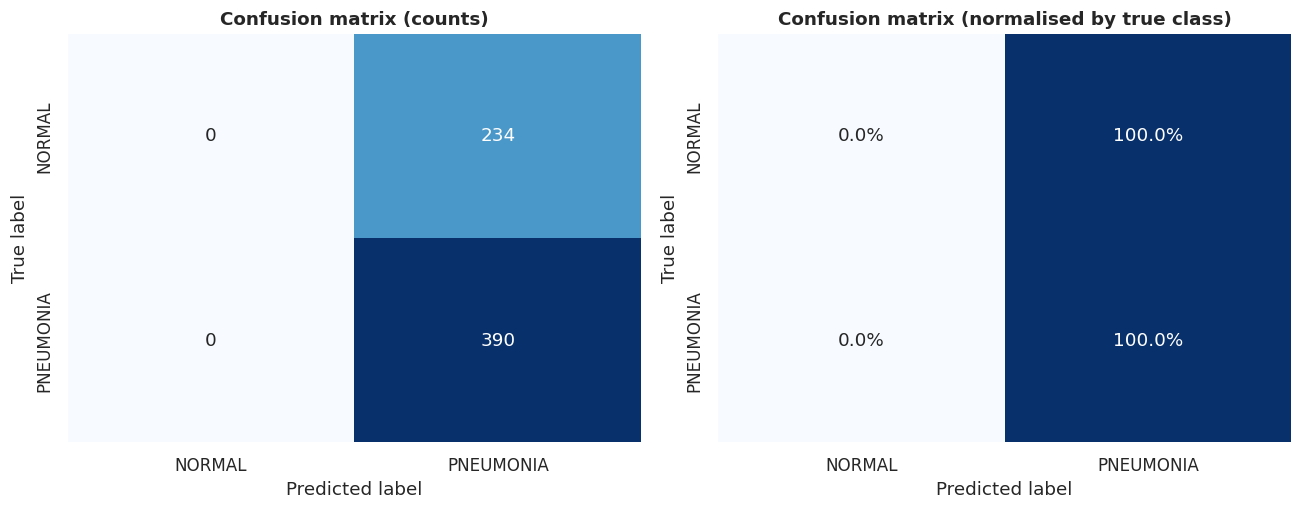

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Confusion matrix (normalised by true class)")
for ax in axes:
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 8.3 Class Distribution Across Splits

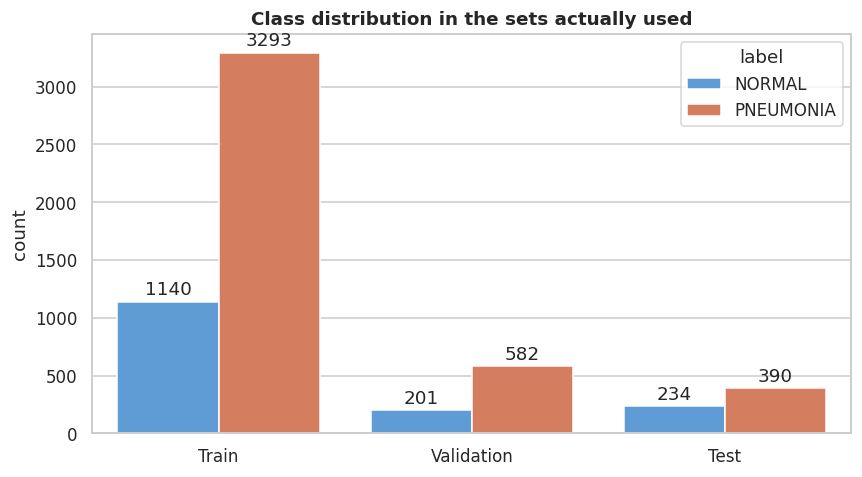

In [22]:
dist = pd.concat([df_train.assign(set="Train"), df_val.assign(set="Validation"), df_test.assign(set="Test")])
plt.figure(figsize=(8, 4.5))
ax = sns.countplot(data=dist, x="set", hue="label", hue_order=CLASS_NAMES,
                   order=["Train", "Validation", "Test"], palette=["#4C9BE8", "#E8744C"])
for container in ax.containers:
    ax.bar_label(container, padding=2)
ax.set_title("Class distribution in the sets actually used")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 8.4 Correct and Incorrect Predictions

/tmp/ipykernel_5246/1841414654.py:17: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


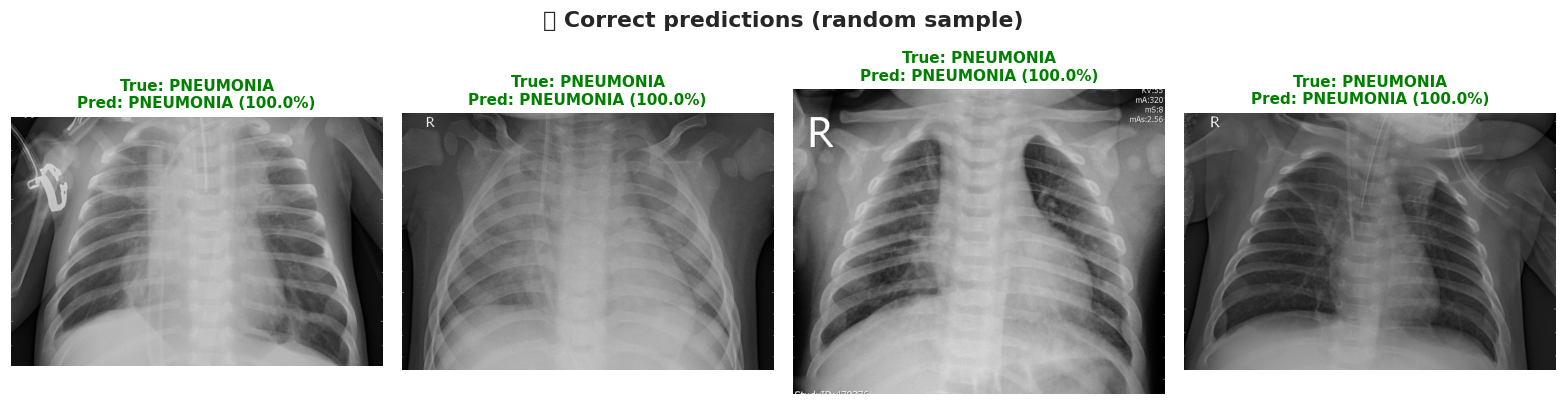

/tmp/ipykernel_5246/1841414654.py:17: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


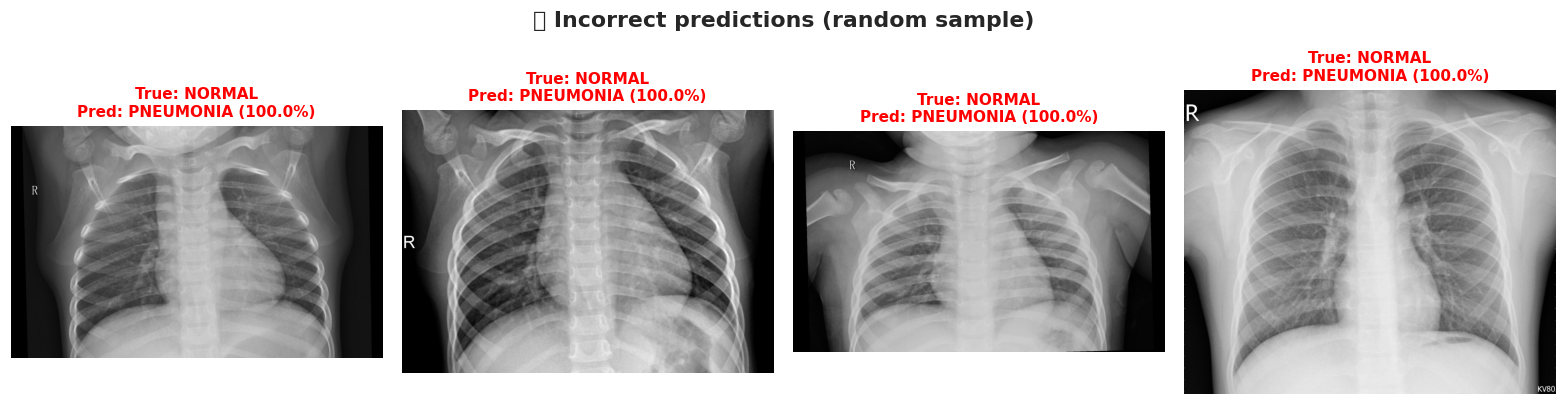

In [23]:
def show_predictions(indices, title, n=4):
    indices = list(indices)[:n]
    if not indices:
        print(f"No examples for: {title}")
        return
    fig, axes = plt.subplots(1, len(indices), figsize=(3.6 * len(indices), 4))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, indices):
        row = df_test.iloc[i]
        pred = int(y_pred[i])
        conf = y_prob[i] if pred == 1 else 1 - y_prob[i]
        ax.imshow(Image.open(row["path"]), cmap="gray")
        ax.set_title(f"True: {row['label']}\nPred: {CLASS_NAMES[pred]} ({conf:.1%})", fontsize=10,
                     color="green" if pred == row["label_id"] else "red")
        ax.axis("off")
    plt.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


pick = np.random.default_rng(SEED)
correct_idx = pick.permutation(np.where(y_pred == y_true)[0])
wrong_idx = pick.permutation(np.where(y_pred != y_true)[0])
show_predictions(correct_idx, "✅ Correct predictions (random sample)")
show_predictions(wrong_idx, "❌ Incorrect predictions (random sample)")

<a id="part-9"></a>
# PART 9 – Prediction on New Images

> ⚠️ **This model is experimental and is NOT a medical diagnostic tool.** Its output must never replace the judgement of a qualified healthcare professional.

The function below loads an X-ray image, applies the same preprocessing as in training, and returns the predicted class and a confidence score (the probability assigned to the predicted class).

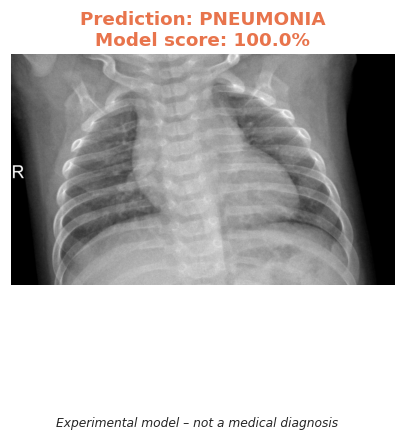

True class: NORMAL    -> predicted: PNEUMONIA (100.0%)


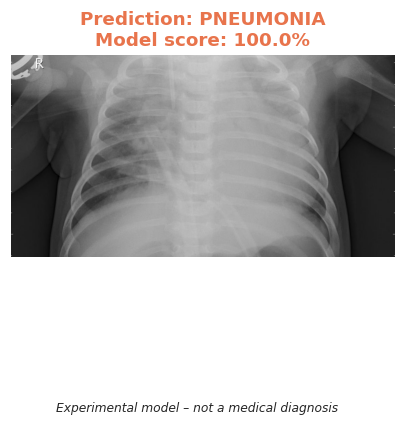

True class: PNEUMONIA -> predicted: PNEUMONIA (100.0%)


In [24]:
def predict_image(image_path, model=None, threshold=THRESHOLD, show=True):
    """Predict NORMAL / PNEUMONIA for one chest X-ray image file."""
    path = Path(image_path)
    if not path.is_file():
        raise FileNotFoundError(f"Image not found: {path}")
    if path.suffix.lower() not in IMG_EXTS:
        raise ValueError(f"Unsupported file type '{path.suffix}'. Expected one of {sorted(IMG_EXTS)}")

    prediction_model = best_model if model is None else model
    x = tf.expand_dims(decode_and_resize(str(path)), 0)
    prob_pneumonia = float(prediction_model.predict(x, verbose=0)[0][0])
    label = CLASS_NAMES[int(prob_pneumonia >= threshold)]
    confidence = prob_pneumonia if label == "PNEUMONIA" else 1 - prob_pneumonia

    if show:
        with Image.open(path) as source_image:
            display_image = source_image.convert("RGB")
        plt.figure(figsize=(4.5, 4.8))
        plt.imshow(display_image)
        plt.title(
            f"Prediction: {label}\nModel score: {confidence:.1%}",
            fontweight="bold",
            color="#E8744C" if label == "PNEUMONIA" else "#4C9BE8",
        )
        plt.axis("off")
        plt.figtext(
            0.5, 0.01,
            "Experimental model – not a medical diagnosis",
            ha="center", fontsize=8, style="italic"
        )
        plt.show()

    return label, confidence


# Demo on one random test image per class.
demo_rng = random.Random(SEED)
for cls in CLASS_NAMES:
    class_paths = df_test[df_test["label"] == cls]["path"].tolist()
    if class_paths:
        sample = demo_rng.choice(class_paths)
        label, conf = predict_image(sample)
        print(f"True class: {cls:9s} -> predicted: {label} ({conf:.1%})")


## 9.1 Try Your Own Image (Optional – run this cell manually)\nRun this cell only when you want to upload a new X-ray image from your computer. It is intentionally separate so that **Run all** does not pause for an upload dialog.

In [25]:
# Optional Google Colab upload: execute this cell manually when needed.\nfrom google.colab import files\n\nuploaded_images = files.upload()\n\nfor image_name in uploaded_images.keys():\n    predicted_label, score = predict_image(image_name)\n    print(f'{image_name}: {predicted_label} (model score: {score:.1%})')

<a id="part-10"></a>
# PART 10 – Conclusion

## 10.1 Summary
We built an end-to-end CNN pipeline for chest X-ray classification: dataset verification, leakage-free patient-aware splitting, class-imbalance handling, a memory-efficient `tf.data` pipeline, a regularised CNN trained from scratch with standard callbacks, evaluation on an untouched test set, and a reusable prediction function. The best model is saved in `.keras` format and can be reloaded without retraining.

## 10.2 Results Actually Obtained
The table below is generated **from the metrics computed in this run** – nothing is typed in by hand.

In [26]:
table_md = "| Metric | Value |\n|---|---|\n" + "\n".join(f"| {k} | {v:.4f} |" for k, v in test_metrics.items())
display(Markdown("### Final test-set results\n\n" + table_md))
display(Markdown(
    f"On the **{len(y_true)}** test images, the model produced **{fp}** false positives "
    f"(normal predicted as pneumonia) and **{fn}** false negatives (pneumonia predicted as normal)."
))

### Final test-set results

| Metric | Value |
|---|---|
| Test Loss | 3.5833 |
| Test Accuracy | 0.6250 |
| Precision (PNEUMONIA) | 0.6250 |
| Recall (PNEUMONIA) | 1.0000 |
| F1-score (PNEUMONIA) | 0.7692 |
| ROC AUC | 0.8138 |

On the **624** test images, the model produced **234** false positives (normal predicted as pneumonia) and **0** false negatives (pneumonia predicted as normal).

## 10.3 Limitations
- **Single-source data:** all images come from one pediatric hospital (patients aged 1–5). Performance on adults or other scanners/hospitals is unknown and likely lower.
- **Label quality and scope:** bacterial and viral pneumonia are merged into one class; labels were assigned by experts but are not individually re-verified here.
- **Class imbalance:** the test set is imbalanced, so accuracy alone can be misleading – always inspect recall, precision and the confusion matrix.
- **No patient identifiers in the Hugging Face mirror:** the validation split is stratified by class, not patient. Images from the same patient could therefore appear across train and validation.
- **Limited validation:** results come from one train/validation split and one run; no confidence intervals or cross-validation were computed.
- **No explainability or clinical validation:** the model has not been audited for the image regions it relies on (shortcut features such as markers or acquisition artefacts are possible) and has no regulatory approval.
- **Non-determinism:** even with fixed seeds, GPU kernels can introduce small run-to-run differences.

## 10.4 Future Improvements
- Transfer learning (e.g. ResNet, EfficientNet, DenseNet pretrained on ImageNet) and fine-tuning.
- Stratified, patient-level **cross-validation** and confidence intervals.
- **Explainability** with Grad-CAM to check that the model focuses on lung regions.
- Decision-threshold tuning to favour recall, and probability calibration.
- External validation on other public chest X-ray datasets.
- Multi-class extension (normal / bacterial / viral pneumonia).

---
*Dataset citation: D. S. Kermany et al., "Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning", Cell, 2018.*